# 03 · Advanced Uplift Modeling: X-learner, Causal Forest, Uncertainty & Robustness

**Research question 3:** *How reliably can heterogeneous treatment effects be estimated?* This notebook also picks the model carried into policy optimization.

Notebook 02 left two facts on the table:
1. The **T-learner** (difference of two noisy regressions) carries almost no held-out signal for spend.
2. The **purchase-propensity** score ranks well for the Women's e-mail because it implicitly learns responsiveness. However, it says nothing about *how many dollars* an e-mail is worth, which break-even and campaign choice need.

#### Candidate CATE estimators (all output dollars of incremental spend)

| Model | Idea | Why it might help here |
|---|---|---|
| **S-learner** | one model, treatment as a feature | regularization shrinks effects toward zero |
| **X-learner** (Künzel et al. 2019) | impute individual effects with the *other* arm's model, then regress them | designed for weak or imbalanced signal |
| **DR-learner** (Kennedy 2020) | regress cross-fitted AIPW pseudo-outcomes on X | unbiased target since e is known |
| **Causal forest** (Wager & Athey 2018; EconML `CausalForestDML`) | honest forest that splits on effect heterogeneity, with residualization | non-linear heterogeneity **with confidence intervals** |
| **Calibrated propensity** (hypothesis tested here) | τ(x) = a + b·p(x): DR-calibrated single-index model on the purchase propensity | could turn the strong Women's propensity ranking into dollars with only 2 causal parameters |

#### Pre-registered selection rule
The model carried forward is the one with the **highest AUGC for spend averaged over both campaigns** (out of fold, development data only). AUGC is the area between the AIPW gain curve and random targeting. If a more complex model does not beat a simpler one by more than one bootstrap standard error of the paired difference, the simpler one is preferred. The test set is not used.

In [1]:
import sys, time, json, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.stats import spearmanr

from src import config, data, evaluation, models, pipeline, plotting as P

P.use_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 140)

df = data.load_raw()
X = data.build_features(df)
splits = pd.read_csv(config.ARTIFACTS_DIR / "splits.csv", index_col=0)
folds = splits["fold"]
dev = (splits["split"] == "dev").to_numpy()
gamma = {o: pd.read_csv(config.ARTIFACTS_DIR / f"oof_gamma_{o}.csv", index_col=0) for o in ["spend", "visit"]}
baselines = {k: pd.read_csv(config.ARTIFACTS_DIR / f"oof_baselines_{k}.csv", index_col=0) for k in config.CAMPAIGNS}
CAMPAIGN_KEYS, PRIMARY = list(config.CAMPAIGNS), config.PRIMARY_CAMPAIGN
assert (splits.loc[dev, "fold"] >= 0).all() and (splits.loc[~dev, "fold"] == -1).all()

## 1 · Cross-fitted CATE estimates

Every model is fitted 5 times per campaign, each time on 4 development folds, and scores the held-out fold. Base learners are histogram gradient boosting with the same regularization as the baselines. Two variants test sensitivity to the main regularization knob:

* the X-learner with heavier leaf constraints;
* the causal forest with a larger minimum leaf.

In [2]:
SPECS = {
    "S-learner": ("s_learner", {}),
    "X-learner": ("x_learner", {}),
    "X-learner (regularized)": ("x_learner", {"min_samples_leaf": 600, "max_leaf_nodes": 8}),
    "DR-learner": ("dr_learner", {}),
    "Calibrated propensity": ("calibrated_propensity", {}),
    "Causal forest": ("causal_forest", {"n_estimators": 400, "min_samples_leaf": 50}),
    "Causal forest (leaf 200)": ("causal_forest", {"n_estimators": 400, "min_samples_leaf": 200}),
}
oof = {}
for key in CAMPAIGN_KEYS:
    t0 = time.time()
    adv = pipeline.cross_fit(df, X, folds, key, SPECS, outcome="spend", include_response=False)
    oof[key] = baselines[key].join(adv)
    print(f"{key}: {adv.shape[1]} models x 5 folds in {time.time() - t0:.0f}s")
    oof[key].to_csv(config.ARTIFACTS_DIR / f"oof_all_{key}.csv")

C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Bhar

C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Bhar

C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Bhar

C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Bhar

C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Bhar

...

C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Bhar

C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Bhar

C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Bhar

C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\BharathJain\Desktop\Modules\New folder\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Bhar

mens: 7 models x 5 folds in 61s


## 2 · Ranking performance on held-out folds

In [3]:
summ = pd.concat({k: pipeline.summarize_rankings(oof[k], gamma["spend"][k].loc[oof[k].index])
                  for k in CAMPAIGN_KEYS}, names=["campaign"])
augc = summ["AUGC"].unstack(0)
augc["mean_AUGC"] = augc.mean(axis=1)
display(augc.sort_values("mean_AUGC", ascending=False).style.format("{:+.4f}").set_caption(
    "AUGC for spend ($ per customer above random, out of fold)"))
summ

campaign,womens,mens,mean_AUGC
model,,,
Purchase propensity,+0.1052,+0.0468,+0.0760
X-learner (regularized),+0.1383,+0.0077,+0.0730
Causal forest (leaf 200),+0.1079,+0.0338,+0.0708
Causal forest,+0.0866,+0.0454,+0.0660
X-learner,+0.1019,+0.0149,+0.0584
DR-learner,+0.0715,+0.0229,+0.0472
Calibrated propensity,+0.0545,-0.0285,+0.0130
S-learner,+0.0404,-0.0176,+0.0114
T-learner,-0.0112,+0.0066,-0.0023


AUGC  gain@30%  gain@30%_se  vs_random  vs_random_se  BLP_slope
campaign model                                                                                      
womens   Purchase propensity       0.1052    0.2456       0.0935     0.1069        0.0743    49.8535
         T-learner                -0.0112    0.1830       0.0810     0.0443        0.0682    -0.0923
         S-learner                 0.0404    0.1976       0.0825     0.0589        0.0689     0.1448
         X-learner                 0.1019    0.3342       0.0922     0.1955        0.0736     0.2214
         X-learner (regularized)   0.1383    0.3449       0.0970     0.2062        0.0761     0.6890
         DR-learner                0.0715    0.2474       0.0942     0.1087        0.0746     0.2738
         Calibrated propensity     0.0545    0.2603       0.0906     0.1215        0.0729     1.0165
         Causal forest             0.0866    0.2763       0.0918     0.1375        0.0734     0.3387
         Causal forest (leaf 200)  0.1079    0.3122       0.1035     0.1735        0.0794     0.7899
mens     Purchase propensity       0.0468    0.3220       0.1145     0.0727        0.0880    32.3258
         T-learner                 0.0066    0.1800       0.0918    -0.0692        0.0766    -0.0389
         S-learner                -0.0176    0.2567       0.1032     0.0075        0.0822    -0.1483
         X-learner                 0.0149    0.2557       0.0903     0.0065        0.0758     0.0925
         X-learner (regularized)   0.0077    0.2850       0.0960     0.0358        0.0786     0.0038
         DR-learner                0.0229    0.3181       0.0872     0.0688        0.0744     0.0370
         Calibrated propensity    -0.0285    0.1893       0.1084    -0.0599        0.0848    -0.2399
         Causal forest             0.0454    0.3415       0.0936     0.0923        0.0774     0.1370
         Causal forest (leaf 200)  0.0338    0.4065       0.1061     0.1573        0.0836     0.3108

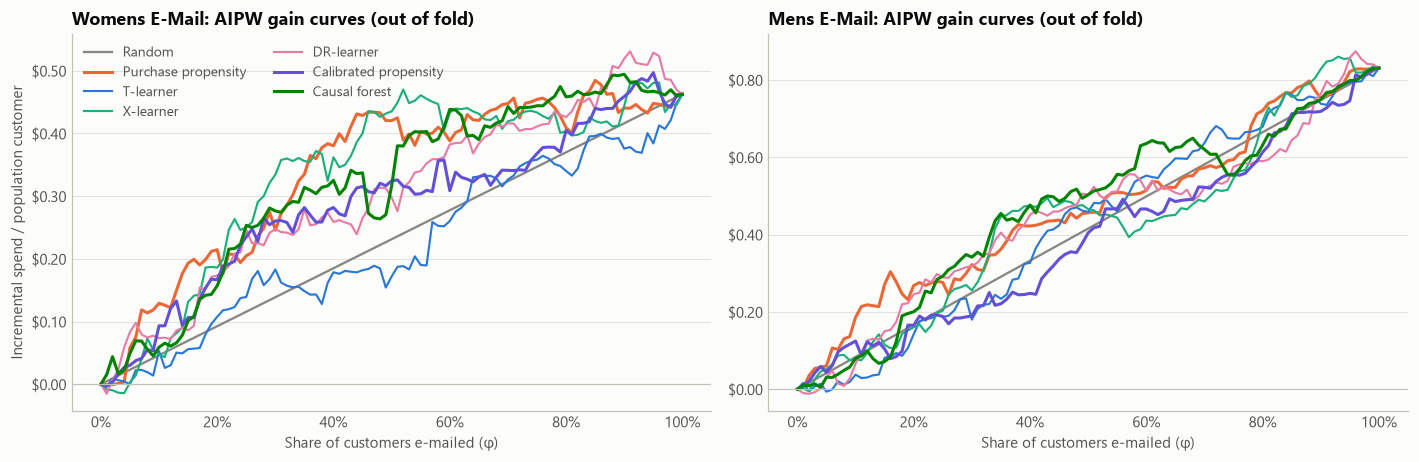

In [4]:
SHOW = ["Purchase propensity", "T-learner", "X-learner", "DR-learner", "Calibrated propensity", "Causal forest"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
grid = evaluation.GRID
for ax, key in zip(axes, CAMPAIGN_KEYS):
    g = gamma["spend"][key].loc[oof[key].index].to_numpy()
    ax.plot([0, 1], [0, g.mean()], color=P.MUTED, lw=1.5, label="Random")
    for name in SHOW:
        ax.plot(grid, evaluation.gain_curve(oof[key][name].to_numpy(), g), color=P.color_for(name),
                lw=2 if name in ("Calibrated propensity", "Causal forest", "Purchase propensity") else 1.4,
                label=name)
    ax.axhline(0, color=P.AXIS, lw=0.8)
    P.percent(ax, "x"); P.dollar(ax)
    ax.set_xlabel("Share of customers e-mailed (φ)")
    ax.set_title(f"{config.CAMPAIGNS[key]}: AIPW gain curves (out of fold)")
axes[0].set_ylabel("Incremental spend / population customer")
axes[0].legend(loc="upper left", ncol=2)
fig.tight_layout(); P.savefig(fig, "03_gain_curves_all_models"); plt.show()

## 3 · Uncertainty

### 3a · Paired bootstrap of AUGC
Customers are resampled with replacement while each customer's out-of-fold score and AIPW score stay fixed, which gives 300 paired replicates. This captures **evaluation** uncertainty for fixed fitted models. Training variability is examined separately in §3d and in notebook 06.

In [5]:
def bootstrap_augc(scores: pd.DataFrame, g: np.ndarray, n_boot=300, seed=0):
    rng = np.random.default_rng(seed)
    n = len(g)
    S = scores.to_numpy()
    out = np.empty((n_boot, S.shape[1]))
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        for j in range(S.shape[1]):
            out[b, j] = evaluation.area_above_random(evaluation.gain_curve(S[idx, j], g[idx]))
    return pd.DataFrame(out, columns=scores.columns)

boot = {k: bootstrap_augc(oof[k], gamma["spend"][k].loc[oof[k].index].to_numpy(), seed=config.SEED)
        for k in CAMPAIGN_KEYS}
boot_mean = (boot["womens"] + boot["mens"]) / 2
ref = "Purchase propensity"
rows = []
for name in boot_mean:
    d = boot_mean[name] - boot_mean[ref]
    rows.append({"model": name, "mean_AUGC": augc.loc[name, "mean_AUGC"],
                 "ci_low": boot_mean[name].quantile(.025), "ci_high": boot_mean[name].quantile(.975),
                 "diff_vs_propensity": augc.loc[name, "mean_AUGC"] - augc.loc[ref, "mean_AUGC"],
                 "diff_se": d.std(), "P(better than propensity)": (d > 0).mean()})
unc = pd.DataFrame(rows).set_index("model").sort_values("mean_AUGC", ascending=False)
unc

,mean_AUGC,ci_low,ci_high,diff_vs_propensity,diff_se,P(better than propensity)
model,,,,,,
Purchase propensity,0.0760,0.0098,0.1457,0.0000,0.0000,0.0000
X-learner (regularized),0.0730,0.0025,0.1367,-0.0030,0.0408,0.4767
Causal forest (leaf 200),0.0708,0.0031,0.1324,-0.0051,0.0367,0.4633
Causal forest,0.0660,0.0064,0.1300,-0.0100,0.0389,0.4400
X-learner,0.0584,-0.0019,0.1200,-0.0176,0.0399,0.3267
DR-learner,0.0472,-0.0197,0.1220,-0.0288,0.0461,0.2800
Calibrated propensity,0.0130,-0.0519,0.0944,-0.0630,0.0275,0.0167
S-learner,0.0114,-0.0506,0.0718,-0.0646,0.0393,0.0567
T-learner,-0.0023,-0.0762,0.0618,-0.0783,0.0425,0.0400


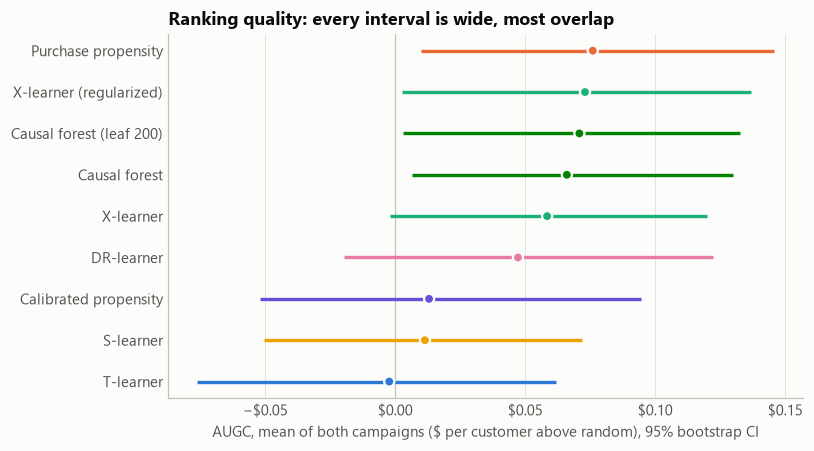

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
u = unc.iloc[::-1]
y = np.arange(len(u))
ax.axvline(0, color=P.AXIS, lw=0.8)
ax.hlines(y, u.ci_low, u.ci_high, color=[P.color_for(n) for n in u.index], lw=2.2)
ax.scatter(u.mean_AUGC, y, color=[P.color_for(n) for n in u.index], s=44, zorder=3, edgecolor=P.SURFACE, linewidth=1.5)
ax.set_yticks(y, u.index); ax.grid(axis="y", visible=False); ax.grid(axis="x")
P.dollar(ax, "x", 2)
ax.set_xlabel("AUGC, mean of both campaigns ($ per customer above random), 95% bootstrap CI")
ax.set_title("Ranking quality: every interval is wide, most overlap")
fig.tight_layout(); P.savefig(fig, "03_augc_bootstrap"); plt.show()

### 3b · Calibration: are the predicted dollar effects the right size?

For each dollar-valued model, the BLP slope of Γ on predicted CATE is shown with a 95% CI (HC2). A slope of **1** means that a \$1 difference in predicted effect corresponds to a \$1 difference in realized effect. A slope of **0** means the predicted variation is noise. A slope between 0 and 1 means the model is directionally right but over-dispersed.

In [7]:
blp = []
for key in CAMPAIGN_KEYS:
    g = gamma["spend"][key].loc[oof[key].index].to_numpy()
    for name in oof[key].columns.drop("Purchase propensity"):
        r = evaluation.calibration_slope(oof[key][name].to_numpy(), g)
        blp.append({"campaign": key, "model": name, **r, "pred_sd": oof[key][name].std()})
blp = pd.DataFrame(blp)
blp.pivot(index="model", columns="campaign", values=["slope", "ci_low", "ci_high", "pred_sd"]).round(3)

slope          ci_low         ci_high        pred_sd       
campaign                    mens  womens    mens  womens    mens womens    mens womens
model                                                                                 
Calibrated propensity    -0.2400  1.0170 -1.6610 -1.3390  1.1820 3.3720  0.2170 0.1190
Causal forest             0.1370  0.3390 -0.2290 -0.1100  0.5020 0.7880  0.8580 0.8410
Causal forest (leaf 200)  0.3110  0.7900 -0.3750  0.0900  0.9960 1.4900  0.4920 0.4450
DR-learner                0.0370  0.2740 -0.2260 -0.0410  0.3000 0.5880  1.0920 0.9700
S-learner                -0.1480  0.1450 -0.5140 -0.4050  0.2170 0.6940  0.8190 0.5370
T-learner                -0.0390 -0.0920 -0.3020 -0.3380  0.2240 0.1530  1.2170 1.0990
X-learner                 0.0930  0.2210 -0.2780 -0.1070  0.4630 0.5500  0.8640 0.7790
X-learner (regularized)   0.0040  0.6890 -0.4730  0.2760  0.4810 1.1020  0.6470 0.6120

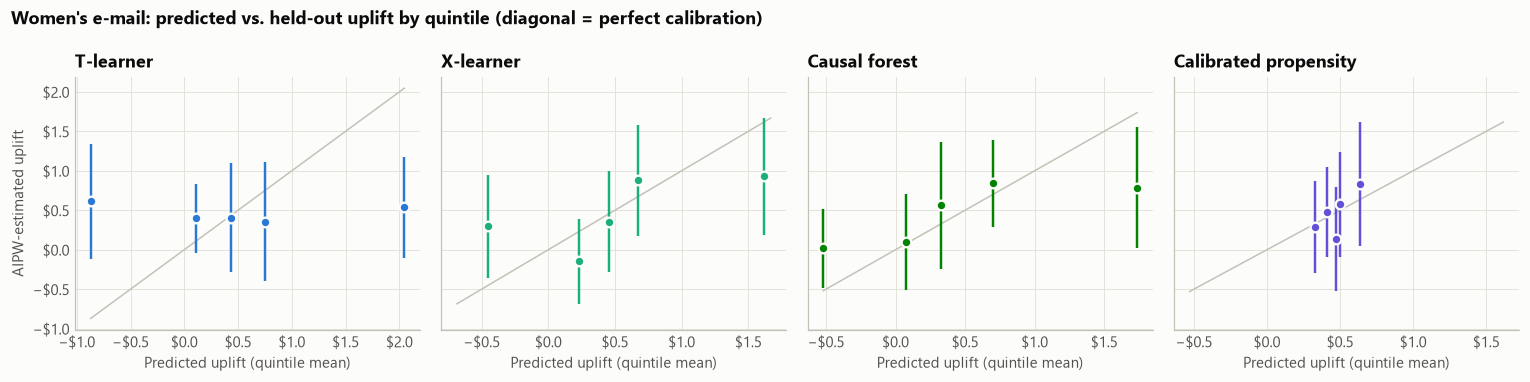

In [8]:
key = PRIMARY
g = gamma["spend"][key].loc[oof[key].index].to_numpy()
CAL_SHOW = ["T-learner", "X-learner", "Causal forest", "Calibrated propensity"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)
for ax, name in zip(axes, CAL_SHOW):
    b = evaluation.uplift_by_bin(oof[key][name].to_numpy(), g, n_bins=5)
    lo = min(b.predicted.min(), b.ci_low.min()); hi = max(b.predicted.max(), b.ci_high.max())
    ax.plot([lo, hi], [lo, hi], color=P.AXIS, lw=1)
    ax.vlines(b.predicted, b.ci_low, b.ci_high, color=P.color_for(name), lw=1.6)
    ax.scatter(b.predicted, b.estimated, color=P.color_for(name), s=40, zorder=3, edgecolor=P.SURFACE, linewidth=1.5)
    ax.set_title(name); P.dollar(ax, "x", 1); P.dollar(ax, "y", 1)
    ax.set_xlabel("Predicted uplift (quintile mean)"); ax.grid(axis="x")
axes[0].set_ylabel("AIPW-estimated uplift")
fig.suptitle("Women's e-mail: predicted vs. held-out uplift by quintile (diagonal = perfect calibration)",
             x=0.01, ha="left", fontsize=11.5, fontweight="bold")
fig.tight_layout(); P.savefig(fig, "03_calibration_quintiles"); plt.show()

### 3c · Causal-forest confidence intervals

The causal forest is the only model here that produces **pointwise confidence intervals** for τ(x). One forest is fitted on folds 1–4 and its intervals are computed on fold 0.

In [9]:
fit_m = ((folds >= 0) & (folds != 0)).to_numpy() & df.segment.isin([config.CAMPAIGNS[PRIMARY], config.CONTROL]).to_numpy()
score_m = (folds == 0).to_numpy()
t_fit = (df.loc[fit_m, "segment"] == config.CAMPAIGNS[PRIMARY]).astype(int).to_numpy()
cf = models.CausalForest(seed=config.SEED, n_estimators=400, min_samples_leaf=50).fit(
    X.loc[fit_m], t_fit, df.loc[fit_m, "spend"].to_numpy())
est = cf.predict(X.loc[score_m])
lo, hi = cf.predict_interval(X.loc[score_m])
ci = pd.DataFrame({"tau": est, "lo": lo, "hi": hi}, index=X.index[score_m])
print(f"Customers scored                       : {len(ci):,}")
print(f"Median CI width                        : ${(ci.hi - ci.lo).median():.2f}")
print(f"Share whose CI excludes 0 (positive)   : {(ci.lo > 0).mean():.1%}")
print(f"Share whose CI excludes 0 (negative)   : {(ci.hi < 0).mean():.1%}")
print(f"Share of point estimates below 0       : {(ci.tau < 0).mean():.1%}")

Customers scored                       : 10,240
Median CI width                        : $2.23
Share whose CI excludes 0 (positive)   : 8.9%
Share whose CI excludes 0 (negative)   : 0.9%
Share of point estimates below 0       : 29.1%


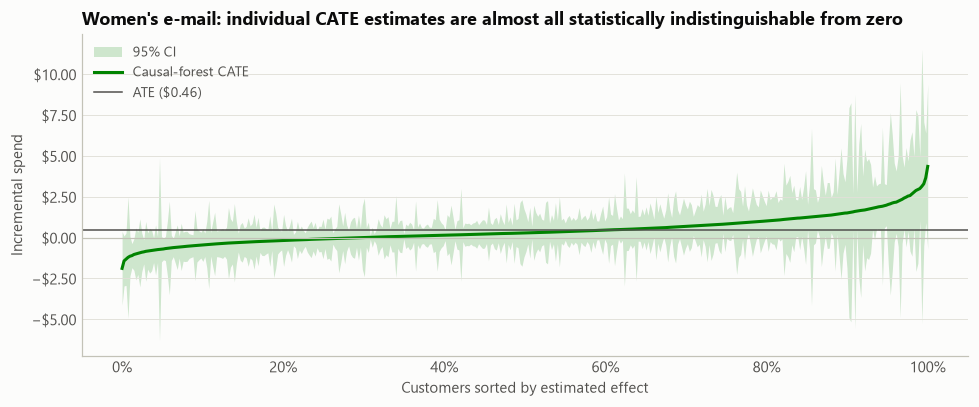

In [10]:
s = ci.sort_values("tau").reset_index(drop=True)
step = max(1, len(s) // 400)
s = s.iloc[::step]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.fill_between(s.index / s.index.max(), s.lo, s.hi, color=P.GREEN, alpha=0.18, lw=0, label="95% CI")
ax.plot(s.index / s.index.max(), s.tau, color=P.GREEN, lw=2, label="Causal-forest CATE")
ax.axhline(0, color=P.AXIS, lw=0.8)
ax.axhline(gamma["spend"][PRIMARY].mean(), color=P.INK_2, lw=1, label=f"ATE (${gamma['spend'][PRIMARY].mean():.2f})")
P.percent(ax, "x"); P.dollar(ax)
ax.set_xlabel("Customers sorted by estimated effect"); ax.set_ylabel("Incremental spend")
ax.set_title("Women's e-mail: individual CATE estimates are almost all statistically indistinguishable from zero")
ax.legend(loc="upper left")
fig.tight_layout(); P.savefig(fig, "03_causal_forest_intervals"); plt.show()

### 3d · Training stability: do rankings survive a change of random seed?

The cell below refits each model on the same 4 folds with three different seeds and compares the scores on fold 0. If a model's ranking changes substantially with only the seed changed, its fine-grained ordering cannot be trusted for targeting.

In [11]:
STAB = {k: SPECS[k] for k in ["X-learner", "X-learner (regularized)", "DR-learner", "Calibrated propensity",
                              "Causal forest", "Causal forest (leaf 200)"]}
STAB["T-learner"] = ("t_learner", {})
fit_all = ((folds >= 0) & (folds != 0)).to_numpy()
runs = [pipeline.fit_and_score(df, X, fit_all, score_m, PRIMARY, STAB, seed=s) for s in [1, 2, 3]]
stab = []
for name in runs[0].columns:
    pairs = [(0, 1), (0, 2), (1, 2)]
    rho = np.mean([spearmanr(runs[a][name], runs[b][name])[0] for a, b in pairs])
    top = [evaluation.top_k_mask(r[name].to_numpy(), 0.3) for r in runs]
    jacc = np.mean([(top[a] & top[b]).sum() / (top[a] | top[b]).sum() for a, b in pairs])
    stab.append({"model": name, "seed_rank_corr": rho, "top30_jaccard": jacc})
stab = pd.DataFrame(stab).set_index("model").sort_values("seed_rank_corr", ascending=False)
stab

,seed_rank_corr,top30_jaccard
model,,
Causal forest (leaf 200),0.9616,0.8425
Causal forest,0.9189,0.7473
X-learner (regularized),0.8489,0.7359
Purchase propensity,0.7724,0.6003
Calibrated propensity,0.7724,0.6003
X-learner,0.7706,0.5920
T-learner,0.6748,0.5450
DR-learner,0.6025,0.4879


### 3e · Do the models agree with each other?

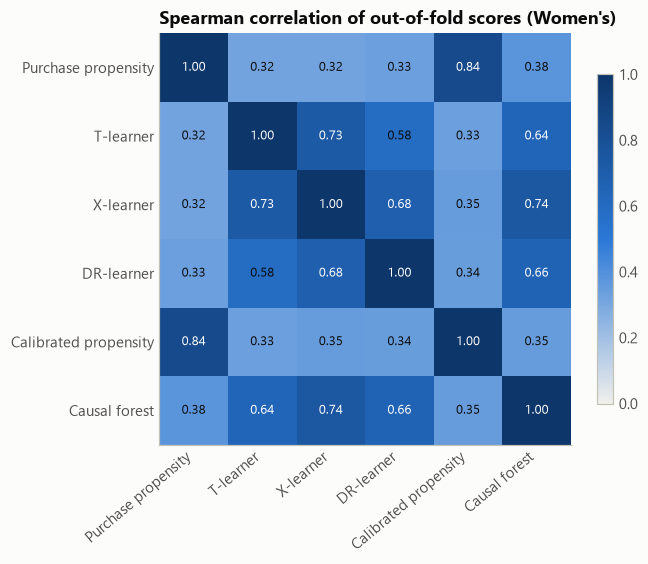

In [12]:
corr = oof[PRIMARY][SHOW].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(corr, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("seq", ["#f0efec", "#2a78d6", "#0d366b"]),
               vmin=0, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right"); ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if corr.iloc[i, j] > 0.6 else P.INK)
ax.grid(False); ax.set_title("Spearman correlation of out-of-fold scores (Women's)")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout(); P.savefig(fig, "03_model_agreement"); plt.show()

## 4 · Robustness

### 4a · A higher-signal KPI: visits
Visits are ~16× more frequent than purchases. If the uplift models' weakness on spend is a **signal-to-noise** problem rather than a method problem, they should do much better when the target is visits. Each model is trained and evaluated on visit.

In [13]:
VSPECS = {"T-learner": ("t_learner", {}), "X-learner": ("x_learner", {}),
          "Calibrated propensity": ("calibrated_propensity", {}),
          "Causal forest": ("causal_forest", {"n_estimators": 400, "min_samples_leaf": 50})}
visit_rows = []
oof_visit = {}
for key in CAMPAIGN_KEYS:
    sc = pipeline.cross_fit(df, X, folds, key, VSPECS, outcome="visit")
    oof_visit[key] = sc
    gv = gamma["visit"][key].loc[sc.index]
    r = pipeline.summarize_rankings(sc, gv)
    r["campaign"] = key
    visit_rows.append(r)
visit_summ = pd.concat(visit_rows).reset_index().set_index(["campaign", "model"])
visit_summ[["AUGC", "gain@30%", "vs_random", "vs_random_se", "BLP_slope"]]

AUGC  gain@30%  vs_random  vs_random_se  BLP_slope
campaign model                                                                     
womens   Purchase propensity   0.0030    0.0154     0.0019        0.0017     1.8111
         T-learner             0.0076    0.0247     0.0112        0.0017     0.5416
         X-learner             0.0076    0.0226     0.0091        0.0017     0.7525
         Calibrated propensity 0.0041    0.0211     0.0076        0.0018     0.8797
         Causal forest         0.0072    0.0224     0.0089        0.0017     0.7459
mens     Purchase propensity   0.0029    0.0269     0.0038        0.0018     1.6814
         T-learner             0.0035    0.0280     0.0049        0.0018     0.3448
         X-learner             0.0028    0.0262     0.0032        0.0018     0.6113
         Calibrated propensity 0.0026    0.0256     0.0026        0.0019     0.6980
         Causal forest         0.0030    0.0253     0.0023        0.0018     0.5116

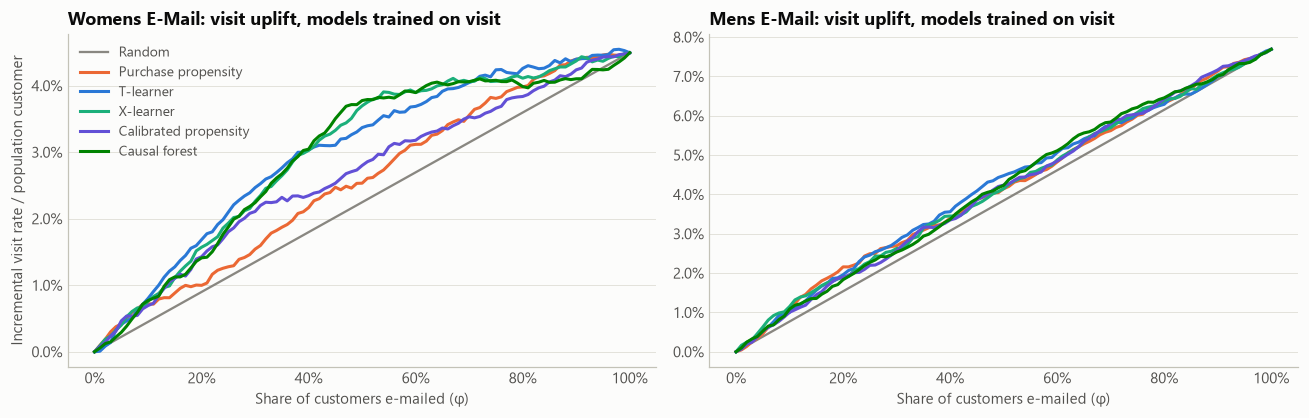

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for ax, key in zip(axes, CAMPAIGN_KEYS):
    gv = gamma["visit"][key].loc[oof_visit[key].index].to_numpy()
    ax.plot([0, 1], [0, gv.mean()], color=P.MUTED, lw=1.5, label="Random")
    for name in oof_visit[key]:
        ax.plot(grid, evaluation.gain_curve(oof_visit[key][name].to_numpy(), gv), color=P.color_for(name), lw=2, label=name)
    P.percent(ax, "x"); P.percent(ax, "y", 1)
    ax.set_xlabel("Share of customers e-mailed (φ)")
    ax.set_title(f"{config.CAMPAIGNS[key]}: visit uplift, models trained on visit")
axes[0].set_ylabel("Incremental visit rate / population customer"); axes[0].legend(loc="upper left")
fig.tight_layout(); P.savefig(fig, "03_gain_curves_visit_models"); plt.show()

### 4b · Sensitivity to regularization
Section 1 already fitted two strengths of regularization for the X-learner and the causal forest. The table below sets them side by side.

In [15]:
pairs = [("X-learner", "X-learner (regularized)"), ("Causal forest", "Causal forest (leaf 200)")]
rows = []
for a, b in pairs:
    for name in (a, b):
        rows.append({"family": a, "variant": name, **augc.loc[name, CAMPAIGN_KEYS + ["mean_AUGC"]].to_dict(),
                     "BLP_womens": blp.query("campaign == 'womens' and model == @name").slope.item()})
pd.DataFrame(rows).set_index(["family", "variant"])

womens   mens  mean_AUGC  BLP_womens
family        variant                                                       
X-learner     X-learner                 0.1019 0.0149     0.0584      0.2214
              X-learner (regularized)   0.1383 0.0077     0.0730      0.6890
Causal forest Causal forest             0.0866 0.0454     0.0660      0.3387
              Causal forest (leaf 200)  0.1079 0.0338     0.0708      0.7899

### 4c · Sensitivity to the base learner: HistGradientBoosting vs Random Forest vs XGBoost

Meta-learners are model-agnostic: any regressor can estimate μ₀, μ₁ and the effect stages. The section-1 results all use **HistGradientBoosting** as the base learner. Here the T-, X- and DR-learners are re-fitted with **Random Forest** (bagged deep trees, 300 trees, 50% feature and row sampling) and **XGBoost** (boosted trees, 300 rounds, lr 0.05, row/column subsampling). The same 5 folds and the same AIPW evaluation scores are used, so the comparison is paired.

The shared regularization knobs are translated per family so "regularized" means the same thing everywhere: minimum leaf size → `min_samples_leaf` (RF) / `min_child_weight` (XGBoost; equal to a minimum sample count under squared loss), and maximum leaves → `max_leaf_nodes` / `max_leaves`.

The columns:
* **AUGC:** whole-curve ranking quality, as in section 2.
* **BLP:** calibration of the dollar predictions.
* **dev profit@30%:** profit of the budgeted decision, the decision-matched criterion discussed in notebook 06.

> This comparison was added after the pre-registered selection in §6 was frozen and the test set was used. It is therefore reported as a **development-data sensitivity analysis** and does not change the selected model.

In [16]:
BASES = {"HistGB": "hgb", "Random forest": "rf", "XGBoost": "xgb"}
FAMILIES = {"T-learner": ("t_learner", {}), "X-learner": ("x_learner", {}),
            "X-learner (regularized)": ("x_learner", {"min_samples_leaf": 600, "max_leaf_nodes": 8}),
            "DR-learner": ("dr_learner", {})}
new_specs = {f"{fam} · {bname}": (key, {**params, "base": b})
             for fam, (key, params) in FAMILIES.items() for bname, b in BASES.items() if b != "hgb"}
oof_base = {}
for key in CAMPAIGN_KEYS:
    t0 = time.time()
    sc = pipeline.cross_fit(df, X, folds, key, new_specs, outcome="spend", include_response=False)
    for fam in FAMILIES:  # HistGB versions were already fitted in section 1
        sc[f"{fam} · HistGB"] = oof[key][fam]
    oof_base[key] = sc
    print(f"{key}: {len(new_specs)} RF/XGBoost models x 5 folds in {time.time() - t0:.0f}s")

rows = []
for fam in FAMILIES:
    for bname in BASES:
        name = f"{fam} · {bname}"
        row = {"learner": fam, "base learner": bname}
        prof, aug = [], []
        for key in CAMPAIGN_KEYS:
            s = oof_base[key][name].to_numpy()
            g = gamma["spend"][key].loc[oof_base[key].index].to_numpy()
            aug.append(evaluation.area_above_random(evaluation.gain_curve(s, g)))
            gain = evaluation.policy_gain(evaluation.top_k_mask(s, 0.3), g)["estimate"]
            prof.append((config.MARGIN * gain - config.COST_PER_CONTACT * 0.3) * config.POPULATION_SIZE)
            row[f"BLP {key}"] = evaluation.calibration_slope(s, g)["slope"]
        row["mean AUGC"], row["dev profit@30% mean"] = np.mean(aug), np.mean(prof)
        row["profit womens"], row["profit mens"] = prof[0], prof[1]
        rows.append(row)
base_cmp = pd.DataFrame(rows).set_index(["learner", "base learner"])
base_cmp.to_csv(config.ARTIFACTS_DIR / "base_learner_comparison.csv")
base_cmp.style.format({"mean AUGC": "{:+.4f}", "BLP womens": "{:.2f}", "BLP mens": "{:.2f}",
                       "dev profit@30% mean": P.money0, "profit womens": P.money0, "profit mens": P.money0})

womens: 8 RF/XGBoost models x 5 folds in 67s


mens: 8 RF/XGBoost models x 5 folds in 63s


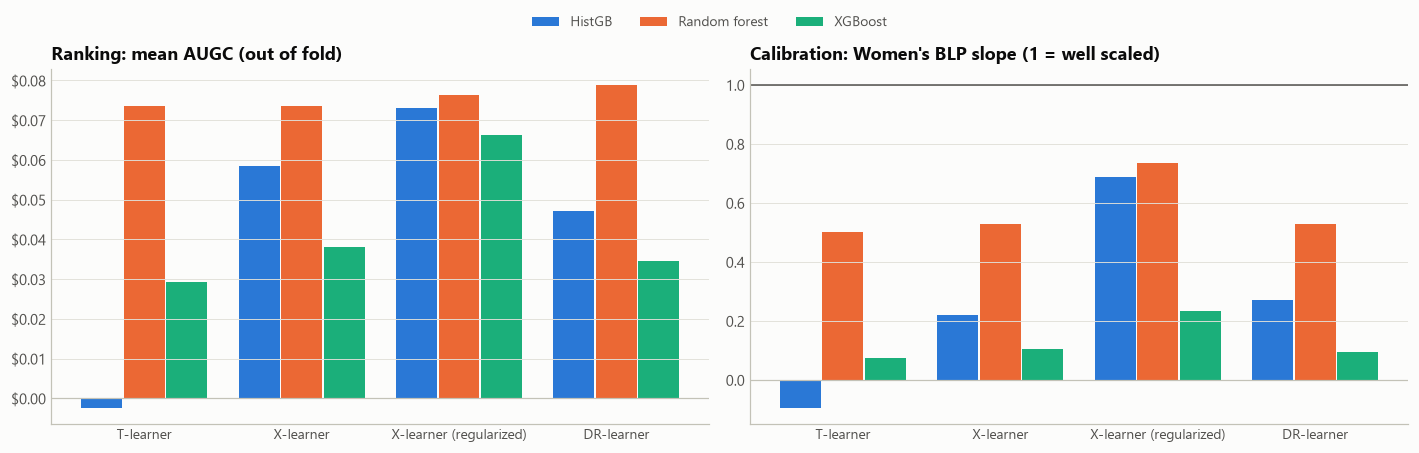

In [17]:
BASE_COLORS = {"HistGB": P.BLUE, "Random forest": P.ORANGE, "XGBoost": P.AQUA}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
fams = list(FAMILIES)
w = 0.26
for ax, (col, title, money) in zip(axes, [("mean AUGC", "Ranking: mean AUGC (out of fold)", False),
                                          ("BLP womens", "Calibration: Women's BLP slope (1 = well scaled)", False)]):
    for j, bname in enumerate(BASES):
        vals = [base_cmp.loc[(f, bname), col] for f in fams]
        ax.bar(np.arange(len(fams)) + (j - 1) * (w + 0.01), vals, width=w, color=BASE_COLORS[bname], label=bname)
    ax.axhline(0, color=P.AXIS, lw=0.8)
    if col.startswith("BLP"):
        ax.axhline(1, color=P.INK_2, lw=1)
    ax.set_xticks(range(len(fams)), fams, fontsize=9)
    ax.set_title(title)
    if col == "mean AUGC":
        P.dollar(ax, "y", 2)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout(); P.savefig(fig, "03_base_learner_comparison"); plt.show()

In [18]:
best = base_cmp["dev profit@30% mean"].idxmax()
best_aug = base_cmp["mean AUGC"].idxmax()
by_base = base_cmp.groupby(level="base learner")[["mean AUGC", "BLP womens", "dev profit@30% mean"]].mean()
display(P.md(f"""**Averaged over the four learners**, by base learner:

| Base learner | mean AUGC | Women's BLP | dev profit@30% |
|---|---|---|---|
""" + "\n".join(f"| {b} | {r['mean AUGC']:+.4f} | {r['BLP womens']:.2f} | {P.money0(r['dev profit@30% mean'])} |"
              for b, r in by_base.iterrows()) + f"""

* Best single combination on the decision-matched criterion: **{best[0]} · {best[1]}** ({P.money0(base_cmp.loc[best, 'dev profit@30% mean'])} per 100k).
* Best on whole-curve AUGC: **{best_aug[0]} · {best_aug[1]}** ({base_cmp.loc[best_aug, 'mean AUGC']:+.4f}).
* The development-set standard error of a profit@30% estimate is about $3.4k per 100k, so differences smaller than that are within noise."""))

**Averaged over the four learners**, by base learner:

| Base learner | mean AUGC | Women's BLP | dev profit@30% |
|---|---|---|---|
| HistGB | +0.0441 | 0.27 | \$6,399 |
| Random forest | +0.0755 | 0.57 | \$7,505 |
| XGBoost | +0.0420 | 0.13 | \$5,840 |

* Best single combination on the decision-matched criterion: **X-learner (regularized) · XGBoost** (\$8,217 per 100k).
* Best on whole-curve AUGC: **DR-learner · Random forest** (+0.0788).
* The development-set standard error of a profit@30% estimate is about \$3.4k per 100k, so differences smaller than that are within noise.

**Interpretation: why bagging beats boosting on this outcome**

* **Random Forest is the strongest base learner here.** It has the best average ranking and, above all, the best calibration. It rescues the T-learner from "no better than random" (AUGC −0.002, BLP −0.09 with HistGB) to the top group (AUGC ≈ +0.074, BLP 0.50). The RF regularized X-learner is the only model in the project with a meaningful **Men's** BLP slope (≈ 0.4).
* **Why:** a forest averages hundreds of trees, each fitted to a different random half of the data. Averaging cancels idiosyncratic noise, and that is exactly what a CATE built from a 0.9%-buyer outcome needs. Boosting fits each new tree to the *residuals* of the previous ones, so on a heavy-tailed outcome it keeps chasing the few large purchases. Differencing two such models (T-learner) or regressing their imputed effects (X-learner) amplifies that noise.
* **XGBoost is the weakest calibrated** (BLP ≈ 0.1). Part of this is configuration: it runs a fixed 300 rounds, while HistGB uses early stopping on a validation split. Early stopping or stronger shrinkage would probably narrow the gap. The ranking of base learners is a property of this outcome and these settings, not a general verdict.
* **Ranking vs decision.** On the decision-matched profit@30% criterion, the top combinations (regularized X-learner with XGBoost, HistGB or RF; RF X- and DR-learners) sit within about $0.9k of each other. That is far inside one standard error (≈ $3.4k), so no base learner is a clear winner for the budgeted decision.
* **Practical recommendation:** for rare, noisy outcomes, start uplift models from a **bagged, heavily regularized** base learner, and judge them on calibration as well as ranking. A natural next step is to carry the RF X-learner into the pooled policy evaluation of notebook 06 as a pre-registered candidate on fresh data.

### 5a · Which features drive effect heterogeneity in the causal forest?

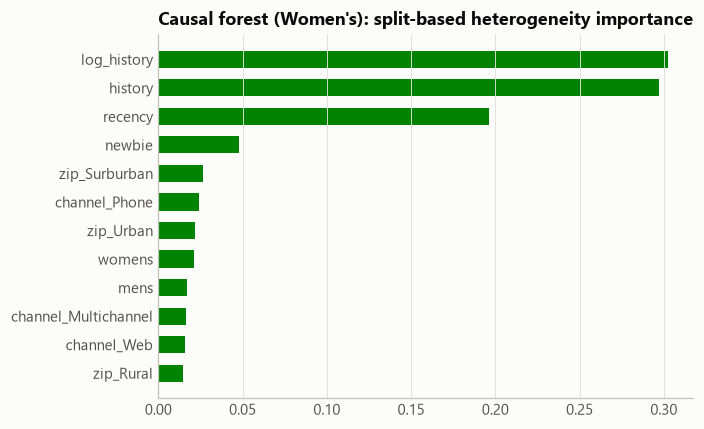

In [19]:
fit_full = dev & df.segment.isin([config.CAMPAIGNS[PRIMARY], config.CONTROL]).to_numpy()
cf_full = models.CausalForest(seed=config.SEED, n_estimators=400, min_samples_leaf=50).fit(
    X.loc[fit_full], (df.loc[fit_full, "segment"] == config.CAMPAIGNS[PRIMARY]).astype(int), df.loc[fit_full, "spend"])
imp = cf_full.feature_importances(X.columns).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.barh(imp.index, imp.values, color=P.GREEN, height=0.6)
ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.set_title("Causal forest (Women's): split-based heterogeneity importance")
fig.tight_layout(); P.savefig(fig, "03_cf_importance"); plt.show()

### 5b · Do model-implied segment effects match the experiment?

A model's average predicted CATE within a segment should match the **observed** experimental effect for that segment (difference in means within the segment, notebook 01). Here both quantities are computed on development data, out of fold, so this is a coarse, segment-level calibration check.

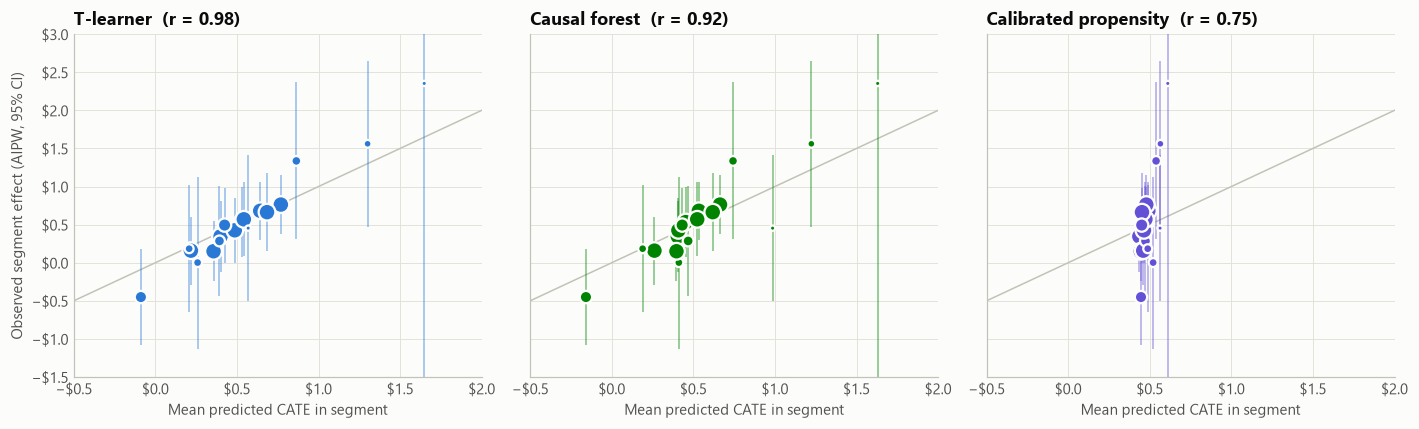

,variable,level,n,observed,obs_lo,obs_hi,T-learner,Causal forest,Calibrated propensity
0,merch_history,both,5124,0.0020,-1.1270,1.1300,0.2590,0.4110,0.5210
1,merch_history,mens only,23016,0.3450,-0.1190,0.8100,0.4000,0.4050,0.4360
2,merch_history,womens only,23060,0.6820,0.2970,1.0660,0.6430,0.5340,0.4910
3,channel,Multichannel,6184,1.3360,0.3060,2.3670,0.8640,0.7430,0.5390
4,channel,Phone,22454,0.1500,-0.2450,0.5460,0.3560,0.3960,0.4450
5,channel,Web,22562,0.5330,0.0750,0.9910,0.5310,0.4530,0.4750
6,newbie,existing,25471,0.1580,-0.2870,0.6030,0.2180,0.2620,0.4600
7,newbie,new,25729,0.7630,0.3790,1.1480,0.7690,0.6630,0.4790
8,zip_code,Rural,7637,0.2860,-0.4360,1.0070,0.3930,0.4680,0.4740
9,zip_code,Surburban,23041,0.4250,-0.0030,0.8530,0.4870,0.4080,0.4640


In [20]:
seg = df.loc[dev].copy()
seg["merch_history"] = np.select([(seg.mens == 1) & (seg.womens == 1), seg.mens == 1, seg.womens == 1],
                                 ["both", "mens only", "womens only"], "neither")
seg["newbie"] = seg["newbie"].map({1: "new", 0: "existing"})
gS = gamma["spend"][PRIMARY].loc[seg.index]
rows = []
for var in ["merch_history", "channel", "newbie", "zip_code", "history_segment"]:
    for lvl, idx in seg.groupby(var).groups.items():
        r = evaluation.mean_ci(gS.loc[idx])
        row = {"variable": var, "level": lvl, "n": len(idx), "observed": r["estimate"], "obs_lo": r["ci_low"], "obs_hi": r["ci_high"]}
        for name in ["T-learner", "Causal forest", "Calibrated propensity"]:
            row[name] = oof[PRIMARY].loc[idx, name].mean()
        rows.append(row)
segcmp = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
lim = (-1.5, 3.0)  # the $1,000+ segment (n ≈ 1k) has a CI of about ±$5 and is clipped
for ax, name in zip(axes, ["T-learner", "Causal forest", "Calibrated propensity"]):
    ax.plot(lim, lim, color=P.AXIS, lw=1)
    ax.set_xlim(-0.5, 2.0); ax.set_ylim(*lim)
    ax.vlines(segcmp[name], segcmp.obs_lo, segcmp.obs_hi, color=P.color_for(name), lw=1, alpha=0.5)
    ax.scatter(segcmp[name], segcmp.observed, s=np.clip(segcmp.n / 150, 12, 120), color=P.color_for(name),
               edgecolor=P.SURFACE, linewidth=1.5, zorder=3)
    r = np.corrcoef(segcmp[name], segcmp.observed)[0, 1]
    ax.set_title(f"{name}  (r = {r:.2f})"); ax.set_xlabel("Mean predicted CATE in segment")
    P.dollar(ax, "x", 1); P.dollar(ax, "y", 1); ax.grid(axis="x")
axes[0].set_ylabel("Observed segment effect (AIPW, 95% CI)")
fig.tight_layout(); P.savefig(fig, "03_segment_calibration"); plt.show()
segcmp.round(3)

A useful contrast: the **T-learner's segment averages track the observed segment effects closely**, even though its individual-level ranking is no better than random (§2). Averaging thousands of customers cancels its individual-level noise. Most of the real heterogeneity here is **between coarse segments**: new vs existing customers, women's-merchandise buyers, multichannel buyers. The extra within-segment variation that flexible learners add is mostly noise. The calibrated-propensity model is nearly flat across segments, because one index cannot express the "new customer" effect.

### 5c · Why did the calibrated-propensity model fail?
Its ranking *within* a training sample equals the propensity ranking whenever b > 0. The cell below checks each fold.

In [21]:
diag = []
for key in CAMPAIGN_KEYS:
    o = oof[key]
    for k in range(config.N_FOLDS):
        m = (folds.loc[o.index] == k).to_numpy()
        diag.append({"campaign": key, "fold": k,
                     "rank corr with propensity": spearmanr(o["Purchase propensity"][m], o["Calibrated propensity"][m])[0],
                     "mean predicted CATE": o["Calibrated propensity"][m].mean(),
                     "sd predicted CATE": o["Calibrated propensity"][m].std()})
pd.DataFrame(diag).set_index(["campaign", "fold"]).unstack(0).round(3)

rank corr with propensity        mean predicted CATE        sd predicted CATE       
campaign                      mens womens                mens womens              mens womens
fold                                                                                         
0                           1.0000 1.0000              0.8110 0.4660            0.0510 0.1330
1                           1.0000 1.0000              0.7440 0.3960            0.4550 0.1420
2                           1.0000 1.0000              0.8640 0.4980            0.0370 0.0720
3                          -1.0000 1.0000              0.8780 0.5030            0.0340 0.0120
4                           1.0000 1.0000              0.8540 0.4840            0.1080 0.1400

The two calibration parameters are estimated from very noisy pseudo-outcomes, and they are **unstable across training samples**. In one Women's fold the slope collapses toward zero. In one Men's fold it turns **negative**, which inverts that fold's ranking (rank correlation −1). A dollar-threshold policy needs effects that are comparable across samples, so this instability is a real defect, not an artefact of pooling folds.

**Lesson:** a low-dimensional causal calibration is only as good as the precision of its few parameters. With ≈ 0.9% buyers, even a 2-parameter fit is underpowered. The hypothesis is reported as tested and rejected.

## 6 · Model selection (development data only)

In [22]:
dollar_models = [m for m in unc.index if m != "Purchase propensity"]
ranked = unc.loc[dollar_models].sort_values("mean_AUGC", ascending=False)
best = ranked.index[0]
complexity = {"Calibrated propensity": 1, "S-learner": 2, "T-learner": 2, "DR-learner": 3,
              "X-learner": 3, "X-learner (regularized)": 3, "Causal forest": 4, "Causal forest (leaf 200)": 4}
# Simplicity tie-break: prefer a simpler model within one paired-bootstrap se of the leader.
chosen = best
for cand in ranked.index[1:]:
    d = boot_mean[best] - boot_mean[cand]
    if complexity[cand] < complexity[chosen] and ranked.loc[best, "mean_AUGC"] - ranked.loc[cand, "mean_AUGC"] < d.std():
        chosen = cand
challenger = next(m for m in ranked.index if m.startswith("Causal forest"))
if challenger == chosen:
    challenger = next(m for m in ranked.index if m != chosen)
selection = {
    "selected_model": chosen, "selected_spec": SPECS[chosen],
    "challenger_model": challenger, "challenger_spec": SPECS[challenger],
    "baseline_models": ["Purchase propensity", "T-learner"],
    "criterion": "mean AUGC (spend) across campaigns, out-of-fold on development data; simplicity tie-break within 1 bootstrap se",
    "dev_mean_AUGC": {m: float(unc.loc[m, "mean_AUGC"]) for m in unc.index},
}
with open(config.ARTIFACTS_DIR / "model_selection.json", "w") as f:
    json.dump(selection, f, indent=2)
display(P.md(f"**Selected model:** `{chosen}`. **Challenger** carried to the test set for comparison: `{challenger}`."))
ranked

**Selected model:** `X-learner (regularized)`. **Challenger** carried to the test set for comparison: `Causal forest (leaf 200)`.

,mean_AUGC,ci_low,ci_high,diff_vs_propensity,diff_se,P(better than propensity)
model,,,,,,
X-learner (regularized),0.0730,0.0025,0.1367,-0.0030,0.0408,0.4767
Causal forest (leaf 200),0.0708,0.0031,0.1324,-0.0051,0.0367,0.4633
Causal forest,0.0660,0.0064,0.1300,-0.0100,0.0389,0.4400
X-learner,0.0584,-0.0019,0.1200,-0.0176,0.0399,0.3267
DR-learner,0.0472,-0.0197,0.1220,-0.0288,0.0461,0.2800
Calibrated propensity,0.0130,-0.0519,0.0944,-0.0630,0.0275,0.0167
S-learner,0.0114,-0.0506,0.0718,-0.0646,0.0393,0.0567
T-learner,-0.0023,-0.0762,0.0618,-0.0783,0.0425,0.0400


## 7 · Conclusions

In [23]:
u = unc
bw = blp[blp.campaign == "womens"].set_index("model").slope
bm = blp[blp.campaign == "mens"].set_index("model").slope
vw = visit_summ.loc["womens"]
v_cate = vw.drop(index=["Purchase propensity", "Calibrated propensity"])
v_z = v_cate["vs_random"] / v_cate["vs_random_se"]
excl = (ci.lo > 0) | (ci.hi < 0)
display(P.md(f"""
1. **Spend heterogeneity is weak and hard to learn.** Across the eight CATE estimators, mean out-of-fold AUGC ranges from
   {u.loc[dollar_models, 'mean_AUGC'].min():+.3f} to {u.loc[dollar_models, 'mean_AUGC'].max():+.3f} dollars per customer, and the bootstrap intervals overlap heavily.
   The causal forest's 95% interval includes zero for **{1 - excl.mean():.0%} of customers**.
2. **Regularization is the main lever, more than the choice of algorithm.** Heavier leaf constraints raise the Women's BLP slope from
   {bw['X-learner']:.2f} to {bw['X-learner (regularized)']:.2f} (X-learner) and from {bw['Causal forest']:.2f} to {bw['Causal forest (leaf 200)']:.2f} (causal forest).
   Their dollar predictions become roughly correctly scaled. Unregularized T/S/DR learners stay far below 1 ({bw['T-learner']:.2f} / {bw['S-learner']:.2f} / {bw['DR-learner']:.2f}).
3. **For ranking alone, the best CATE models tie with the purchase-propensity baseline.** The selected model's paired AUGC difference is
   {u.loc[chosen, 'diff_vs_propensity']:+.3f} ± {u.loc[chosen, 'diff_se']:.3f}. What they add is a **dollar scale**, which break-even and per-customer campaign choice require and a propensity score lacks.
   Notebook 04 tests whether that matters for profit.
4. **The Men's e-mail has little learnable spend heterogeneity.** Among the section-1 models no Men's BLP interval excludes zero (best slope {bm.max():.2f}), consistent with the Wald test in notebook 01. The one partial exception is the Random-Forest X-learner in §4c (slope ≈ {base_cmp.loc[('X-learner (regularized)', 'Random forest'), 'BLP mens']:.2f}).
8. **Base learner matters as much as meta-learner (§4c).** Random Forest beats HistGB and XGBoost on average ranking (mean AUGC {by_base.loc['Random forest', 'mean AUGC']:+.3f} vs {by_base.loc['HistGB', 'mean AUGC']:+.3f} / {by_base.loc['XGBoost', 'mean AUGC']:+.3f}) and calibration (Women's BLP {by_base.loc['Random forest', 'BLP womens']:.2f} vs {by_base.loc['HistGB', 'BLP womens']:.2f} / {by_base.loc['XGBoost', 'BLP womens']:.2f}). Bagging's variance reduction suits a rare, noisy outcome.
5. **The KPI matters as much as the method.** Trained on **visits**, the T/X/causal-forest models reach Women's AUGC of
   {v_cate['AUGC'].min():.4f}–{v_cate['AUGC'].max():.4f}, about **{v_cate['AUGC'].mean() / vw.loc['Purchase propensity', 'AUGC']:.1f}× the propensity ranking's {vw.loc['Purchase propensity', 'AUGC']:.4f}**.
   They beat random targeting at 30% coverage by {v_z.min():.0f}–{v_z.max():.0f} standard errors. The spend problem is signal-to-noise (≈ 0.9% buyers), not a broken method.
6. **The calibrated-propensity hypothesis was rejected.** Its 2 calibration parameters are unstable across training samples (§5c).
7. **Chosen for notebook 04:** `{chosen}` (selected), with `{challenger}` as the challenger, plus the purchase-propensity, T-learner, random and treat-all baselines.
"""))


1. **Spend heterogeneity is weak and hard to learn.** Across the eight CATE estimators, mean out-of-fold AUGC ranges from
   -0.002 to +0.073 dollars per customer, and the bootstrap intervals overlap heavily.
   The causal forest's 95% interval includes zero for **90% of customers**.
2. **Regularization is the main lever, more than the choice of algorithm.** Heavier leaf constraints raise the Women's BLP slope from
   0.22 to 0.69 (X-learner) and from 0.34 to 0.79 (causal forest).
   Their dollar predictions become roughly correctly scaled. Unregularized T/S/DR learners stay far below 1 (-0.09 / 0.14 / 0.27).
3. **For ranking alone, the best CATE models tie with the purchase-propensity baseline.** The selected model's paired AUGC difference is
   -0.003 ± 0.041. What they add is a **dollar scale**, which break-even and per-customer campaign choice require and a propensity score lacks.
   Notebook 04 tests whether that matters for profit.
4. **The Men's e-mail has little learnable spend heterogeneity.** Among the section-1 models no Men's BLP interval excludes zero (best slope 0.31), consistent with the Wald test in notebook 01. The one partial exception is the Random-Forest X-learner in §4c (slope ≈ 0.41).
8. **Base learner matters as much as meta-learner (§4c).** Random Forest beats HistGB and XGBoost on average ranking (mean AUGC +0.076 vs +0.044 / +0.042) and calibration (Women's BLP 0.57 vs 0.27 / 0.13). Bagging's variance reduction suits a rare, noisy outcome.
5. **The KPI matters as much as the method.** Trained on **visits**, the T/X/causal-forest models reach Women's AUGC of
   0.0072–0.0076, about **2.5× the propensity ranking's 0.0030**.
   They beat random targeting at 30% coverage by 5–7 standard errors. The spend problem is signal-to-noise (≈ 0.9% buyers), not a broken method.
6. **The calibrated-propensity hypothesis was rejected.** Its 2 calibration parameters are unstable across training samples (§5c).
7. **Chosen for notebook 04:** `X-learner (regularized)` (selected), with `Causal forest (leaf 200)` as the challenger, plus the purchase-propensity, T-learner, random and treat-all baselines.
